# Board Games Data Mining
## 4. Classification

### 4.0 Setup and Data Loading

The target is `Rating`, encoded as:
- `1` = Low
- `2` = Medium
- `3` = High

We used a 70/30 stratified train/test split and evaluates the classifiers with accuracy, precision, recall, F1-score, confusion matrix, and One-vs-Rest ROC curves.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.preprocessing import MinMaxScaler, label_binarize, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_curve,
    auc,
    roc_auc_score,
)


In [2]:
# Robust path search for the prepared dataset.
candidate_paths = [
    Path("DM1_game_dataset_prepared.csv"),
    Path("data/DM1_game_dataset_prepared.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Prepared dataset not found. Expected 'DM1_game_dataset_prepared.csv' "
        "either in the current folder or inside a 'data/' folder."
    )

df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Loaded: DM1_game_dataset_prepared.csv
Shape: (20671, 24)


,YearPublished,AvgPlaytime,GameWeight,MfgAgeRec,MinPlayers,MaxPlayers,Ranking,Rating,SemanticString,NumOwned,...,IsReimplementation,Kickstarted,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,2014,3.433987,1.8333,15.0,2,4,0.499238,1,assassin s creed arena game description publis...,6.270988,...,False,False,False,False,False,False,False,False,False,False
1,2021,2.917771,1.0000,8.0,2,5,0.499238,2,bag of chips bag chip party game face crucial ...,4.290459,...,False,False,False,False,False,False,False,False,False,False
2,2020,4.510860,3.6667,12.0,1,5,0.499238,3,gùgōng deluxe big box big box contain componen...,6.727432,...,False,False,False,False,False,False,False,False,False,False
3,2004,3.044522,1.3077,10.0,2,2,0.499238,1,letterflip publisherthe reveal game secret wor...,5.043425,...,False,False,False,False,False,False,False,False,False,False
4,2019,2.917771,1.5000,8.0,2,4,0.499238,2,treasures of cibola rescue mayan treasure easy...,5.342334,...,False,False,False,False,False,False,False,False,False,False


In [3]:
# Make Rating conversion safe even if the cell is executed more than once.
rating_map = {
    "low": 1,
    "medium": 2,
    "high": 3,
}

if not pd.api.types.is_numeric_dtype(df["Rating"]):
    df["Rating"] = (
        df["Rating"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map(rating_map)
    )

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

print("Rating distribution:")
display(df["Rating"].value_counts(dropna=False).sort_index())


Rating distribution:


Rating
1    6666
2    9217
3    4788
Name: count, dtype: int64

### Feature sets

In [4]:
COMMON_FEATURES = [
    "YearPublished",
    "MfgAgeRec",
    "MinPlayers",
    "MaxPlayers",
    "AvgPlaytime",
    "GameWeight",
    "NumOwned",
    "NumDemand",
    "NumAlternates",
    "NumExpansions",
    "NumImplementations",
    "Ranking",
]

NB_FEATURES = [
    "YearPublished",
    "MfgAgeRec",
    "MinPlayers",
    "MaxPlayers",
    "AvgPlaytime",
    "GameWeight",
    "NumOwned",
    "NumDemand",
    "NumAlternates",
    "NumExpansions",
    "NumImplementations",
]

missing_common = [c for c in COMMON_FEATURES if c not in df.columns]
missing_nb = [c for c in NB_FEATURES if c not in df.columns]

if missing_common or missing_nb:
    raise KeyError(
        f"Missing columns. COMMON: {missing_common}; NB: {missing_nb}"
    )

classification_df = df[COMMON_FEATURES + ["Rating"]].dropna().copy()

X = classification_df[COMMON_FEATURES]
y = classification_df["Rating"].astype(int)

print("Rows used for KNN / Decision Tree:", len(classification_df))
print("Features:", len(COMMON_FEATURES))
display(y.value_counts(normalize=True).sort_index().rename("proportion"))


Rows used for KNN / Decision Tree: 20671
Features: 12


Rating
1    0.322481
2    0.445890
3    0.231629
Name: proportion, dtype: float64

In [5]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train size:", len(X_train))
print("Test size :", len(X_test))
print("\nTest class counts:")
display(y_test.value_counts().sort_index())


Train size: 14469
Test size : 6202

Test class counts:


Rating
1    2000
2    2765
3    1437
Name: count, dtype: int64

### Evaluation helpers

In [6]:
CLASS_NAMES = ["Low (1)", "Medium (2)", "High (3)"]
CLASSES = np.array([1, 2, 3])

def evaluate_classifier(model, X_test, y_test, title):
    y_pred = model.predict(X_test)

    print(f"{title}")
    print("-" * len(title))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")
    print()
    print(classification_report(
        y_test,
        y_pred,
        labels=CLASSES,
        target_names=CLASS_NAMES,
        digits=3,
        zero_division=0,
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=CLASSES,
        display_labels=CLASS_NAMES,
    )
    plt.title(f"{title} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return {
        "model": title,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
    }


def plot_multiclass_roc(model, X_test, y_test, title):
    if not hasattr(model, "predict_proba"):
        print(f"{title} does not expose predict_proba().")
        return

    y_score = model.predict_proba(X_test)
    y_bin = label_binarize(y_test, classes=CLASSES)

    plt.figure(figsize=(7, 5))

    aucs = []
    for i, class_value in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
        class_auc = auc(fpr, tpr)
        aucs.append(class_auc)
        plt.plot(fpr, tpr, label=f"Class {class_value} (AUC={class_auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{title} - One-vs-Rest ROC")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Macro ROC-AUC:", round(
        roc_auc_score(y_bin, y_score, average="macro", multi_class="ovr"),
        4
    ))


## 4.1 K-Nearest Neighbors (KNN)

- `MinMaxScaler` outperformed `StandardScaler`;
- distance weighting outperformed uniform weighting;
- Manhattan distance was the best metric among the alternatives tested;
- cross-validation over `k = 1, ..., 50` selected `k = 21`;
- model selection used macro F1 because the target classes are imbalanced.

,k,mean_macro_f1,std_macro_f1
32,33,0.729320,0.011680
36,37,0.729017,0.009582
44,45,0.728770,0.010820
31,32,0.728569,0.010569
42,43,0.728543,0.010476
34,35,0.728494,0.008557
41,42,0.728291,0.009364
28,29,0.728273,0.009764
46,47,0.728128,0.009075
45,46,0.728068,0.009766


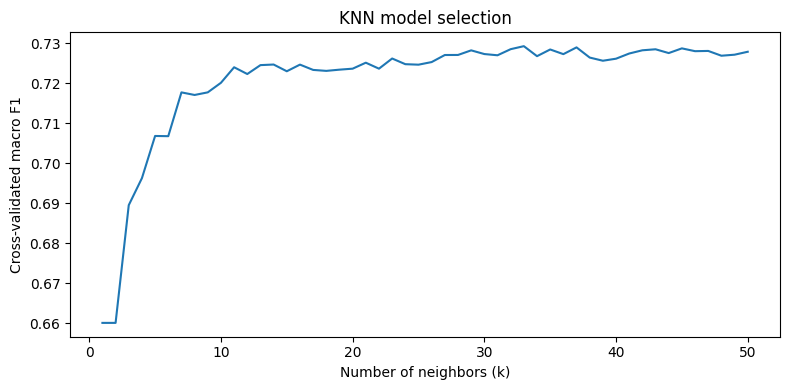

In [7]:
RUN_KNN_CV = True

if RUN_KNN_CV:
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    knn_cv_rows = []

    for k in range(1, 51):
        model = Pipeline([
            ("scale", MinMaxScaler()),
            ("knn", KNeighborsClassifier(
                n_neighbors=k,
                weights="distance",
                metric="manhattan",
            )),
        ])

        scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring="f1_macro",
            n_jobs=-1,
        )

        knn_cv_rows.append({
            "k": k,
            "mean_macro_f1": scores.mean(),
            "std_macro_f1": scores.std(),
        })

    knn_cv_results = pd.DataFrame(knn_cv_rows)
    display(knn_cv_results.sort_values("mean_macro_f1", ascending=False).head(10))

    plt.figure(figsize=(8, 4))
    plt.plot(knn_cv_results["k"], knn_cv_results["mean_macro_f1"])
    plt.xlabel("Number of neighbors (k)")
    plt.ylabel("Cross-validated macro F1")
    plt.title("KNN model selection")
    plt.tight_layout()
    plt.show()
else:
    print("KNN k-search skipped. Set RUN_KNN_CV = True to reproduce the CV sweep.")


KNN
---
Accuracy: 0.7177
Macro F1: 0.7147

              precision    recall  f1-score   support

     Low (1)      0.757     0.748     0.752      2000
  Medium (2)      0.671     0.754     0.710      2765
    High (3)      0.779     0.607     0.682      1437

    accuracy                          0.718      6202
   macro avg      0.736     0.703     0.715      6202
weighted avg      0.724     0.718     0.717      6202



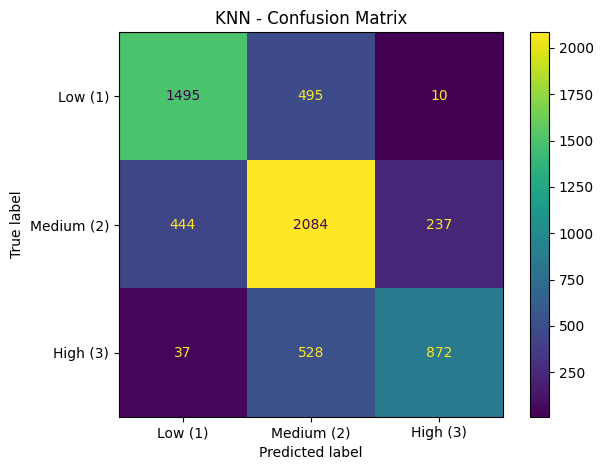

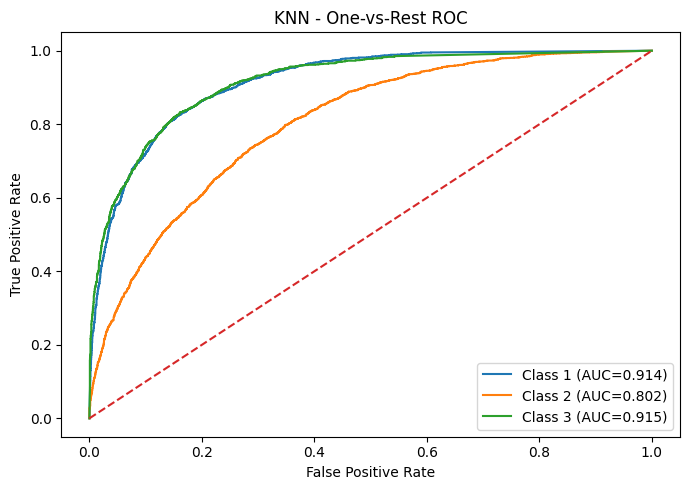

Macro ROC-AUC: 0.8773


In [8]:
knn_model = Pipeline([
    ("scale", MinMaxScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=21,
        weights="distance",
        metric="manhattan",
    )),
])

knn_model.fit(X_train, y_train)

knn_metrics = evaluate_classifier(
    knn_model,
    X_test,
    y_test,
    "KNN",
)

plot_multiclass_roc(
    knn_model,
    X_test,
    y_test,
    "KNN",
)


## 4.2 Naïve Bayes

We evaluated both GaussianNB on continuous variables and CategoricalNB on discretized versions of the same variables.

In [9]:
nb_df = df[NB_FEATURES + ["Rating"]].dropna().copy()

X_nb = nb_df[NB_FEATURES]
y_nb = nb_df["Rating"].astype(int)

X_nb_train, X_nb_test, y_nb_train, y_nb_test = train_test_split(
    X_nb,
    y_nb,
    test_size=0.30,
    stratify=y_nb,
    random_state=RANDOM_STATE,
)

print("Rows used for Naive Bayes:", len(nb_df))


Rows used for Naive Bayes: 20671


Gaussian Naive Bayes
--------------------
Accuracy: 0.6121
Macro F1: 0.6136

              precision    recall  f1-score   support

     Low (1)      0.591     0.776     0.671      2000
  Medium (2)      0.622     0.504     0.557      2765
    High (3)      0.635     0.592     0.613      1437

    accuracy                          0.612      6202
   macro avg      0.616     0.624     0.614      6202
weighted avg      0.615     0.612     0.607      6202



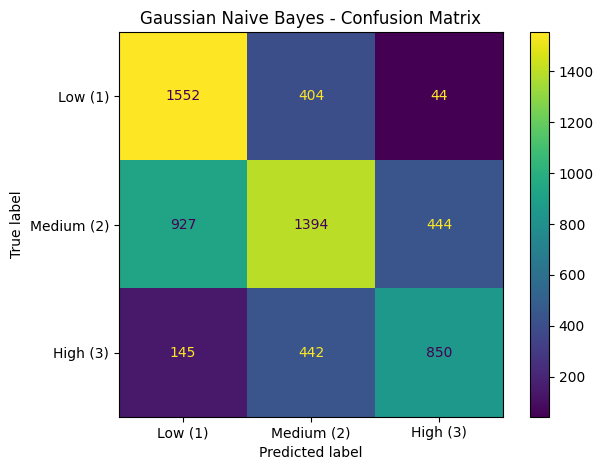

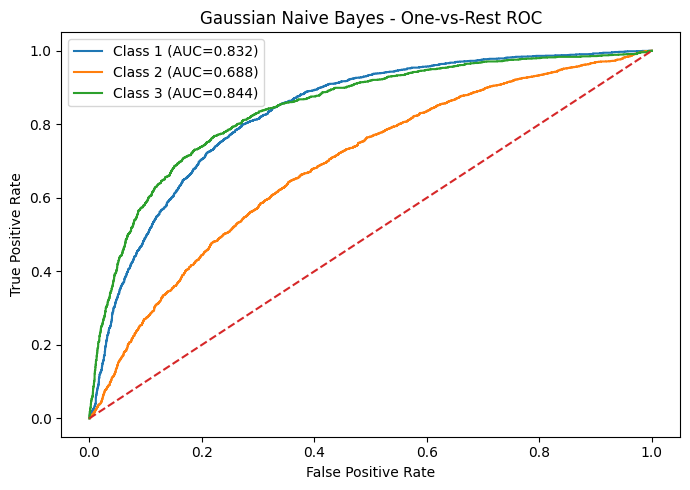

Macro ROC-AUC: 0.7881


In [10]:
gaussian_nb_model = Pipeline([
    ("scale", MinMaxScaler()),
    ("model", GaussianNB()),
])

gaussian_nb_model.fit(X_nb_train, y_nb_train)

gaussian_nb_metrics = evaluate_classifier(
    gaussian_nb_model,
    X_nb_test,
    y_nb_test,
    "Gaussian Naive Bayes",
)

plot_multiclass_roc(
    gaussian_nb_model,
    X_nb_test,
    y_nb_test,
    "Gaussian Naive Bayes",
)


Categorical Naive Bayes (10 quantile bins)
------------------------------------------
Accuracy: 0.6429
Macro F1: 0.6464

              precision    recall  f1-score   support

     Low (1)      0.655     0.735     0.692      2000
  Medium (2)      0.629     0.578     0.602      2765
    High (3)      0.648     0.641     0.644      1437

    accuracy                          0.643      6202
   macro avg      0.644     0.651     0.646      6202
weighted avg      0.642     0.643     0.641      6202



/Users/sarabiiavasco/Codice/venv/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/sarabiiavasco/Codice/venv/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/sarabiiavasco/Codice/venv/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/sarabiiavasco/Codice/venv/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.wa

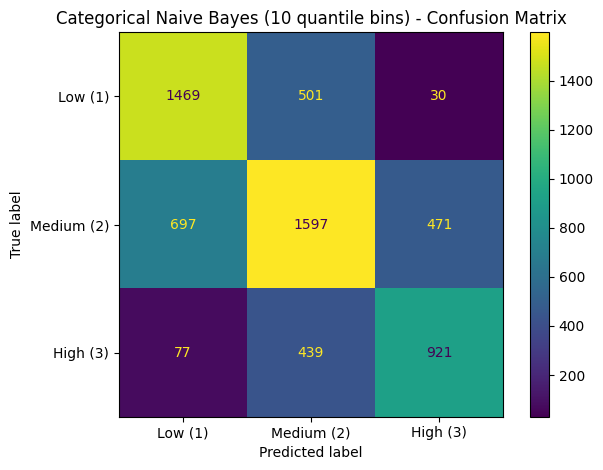

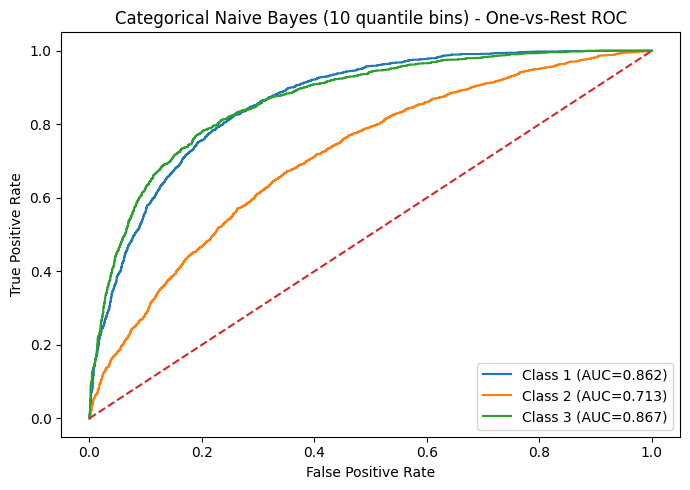

Macro ROC-AUC: 0.814


In [11]:
categorical_nb_model = Pipeline([
    (
        "discretize",
        KBinsDiscretizer(
            n_bins=10,
            encode="ordinal",
            strategy="quantile",
            subsample=None,
        ),
    ),
    ("model", CategoricalNB()),
])

categorical_nb_model.fit(X_nb_train, y_nb_train)

categorical_nb_metrics = evaluate_classifier(
    categorical_nb_model,
    X_nb_test,
    y_nb_test,
    "Categorical Naive Bayes (10 quantile bins)",
)

plot_multiclass_roc(
    categorical_nb_model,
    X_nb_test,
    y_nb_test,
    "Categorical Naive Bayes (10 quantile bins)",
)


## 4.3 Decision Tree

- criterion = `entropy`;
- `max_depth = 8`;
- `min_samples_split = 0.01`;
- `min_samples_leaf = 30`.

We applied cost-complexity pruning and reported a selected `ccp_alpha ≈ 5.95 × 10⁻⁴`, reducing the tree from 219 to 191 nodes without materially changing test performance.

,max_depth,train_accuracy,test_accuracy,test_macro_f1
0,1,0.510471,0.509029,0.382729
1,2,0.599696,0.589971,0.564246
2,3,0.652706,0.643180,0.633983
3,4,0.669915,0.655272,0.646484
4,5,0.692515,0.670751,0.662779
5,6,0.709862,0.682844,0.672197
6,7,0.724169,0.692841,0.687369
7,8,0.731840,0.700419,0.696653
8,9,0.738199,0.702677,0.701089
9,10,0.740203,0.702999,0.703174


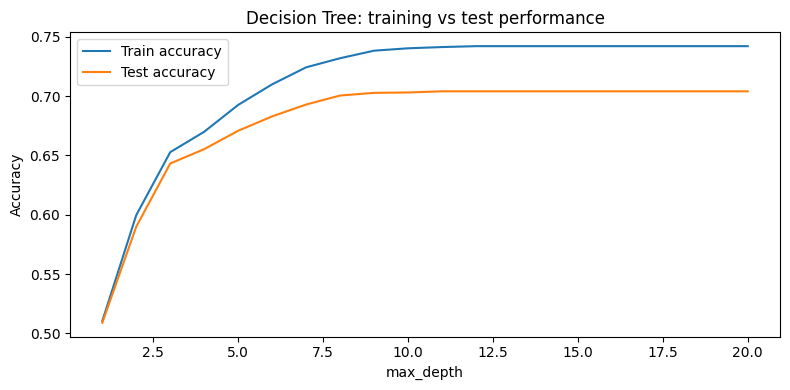

In [12]:
# Inspect train/test behaviour as tree depth changes.
depth_rows = []

for depth in range(1, 21):
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=depth,
        min_samples_split=0.01,
        min_samples_leaf=30,
        random_state=RANDOM_STATE,
    )
    model.fit(X_train, y_train)

    depth_rows.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test)),
        "test_macro_f1": f1_score(
            y_test,
            model.predict(X_test),
            average="macro",
        ),
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results)

plt.figure(figsize=(8, 4))
plt.plot(depth_results["max_depth"], depth_results["train_accuracy"], label="Train accuracy")
plt.plot(depth_results["max_depth"], depth_results["test_accuracy"], label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: training vs test performance")
plt.legend()
plt.tight_layout()
plt.show()


Decision Tree (entropy)
-----------------------
Accuracy: 0.7004
Macro F1: 0.6967

              precision    recall  f1-score   support

     Low (1)      0.748     0.733     0.740      2000
  Medium (2)      0.653     0.737     0.692      2765
    High (3)      0.748     0.586     0.657      1437

    accuracy                          0.700      6202
   macro avg      0.717     0.685     0.697      6202
weighted avg      0.706     0.700     0.700      6202



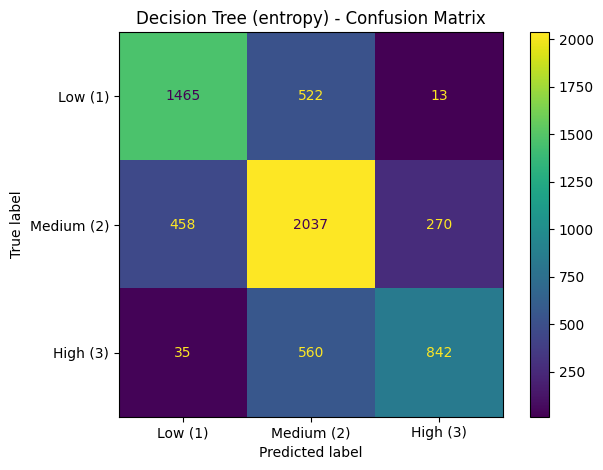

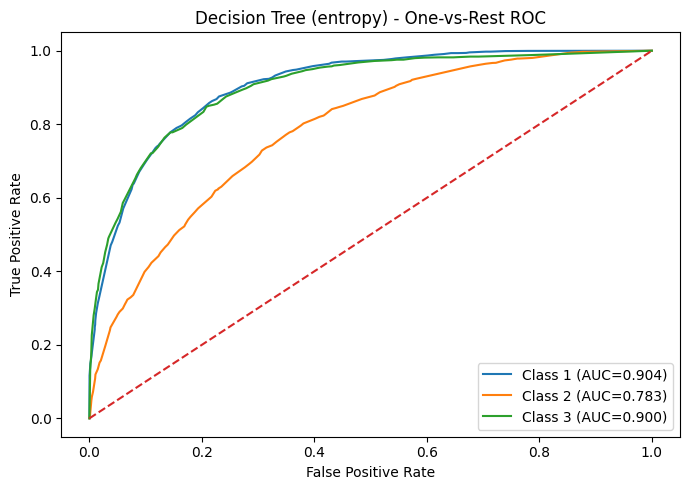

Macro ROC-AUC: 0.8622
Nodes: 215
Leaves: 108
Depth: 8


In [13]:
tree_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=8,
    min_samples_split=0.01,
    min_samples_leaf=30,
    random_state=RANDOM_STATE,
)

tree_model.fit(X_train, y_train)

tree_metrics = evaluate_classifier(
    tree_model,
    X_test,
    y_test,
    "Decision Tree (entropy)",
)

plot_multiclass_roc(
    tree_model,
    X_test,
    y_test,
    "Decision Tree (entropy)",
)

print("Nodes:", tree_model.tree_.node_count)
print("Leaves:", tree_model.get_n_leaves())
print("Depth:", tree_model.get_depth())


Pruned Decision Tree
--------------------
Accuracy: 0.6986
Macro F1: 0.6938

              precision    recall  f1-score   support

     Low (1)      0.742     0.746     0.744      2000
  Medium (2)      0.652     0.731     0.690      2765
    High (3)      0.750     0.571     0.648      1437

    accuracy                          0.699      6202
   macro avg      0.715     0.682     0.694      6202
weighted avg      0.704     0.699     0.697      6202



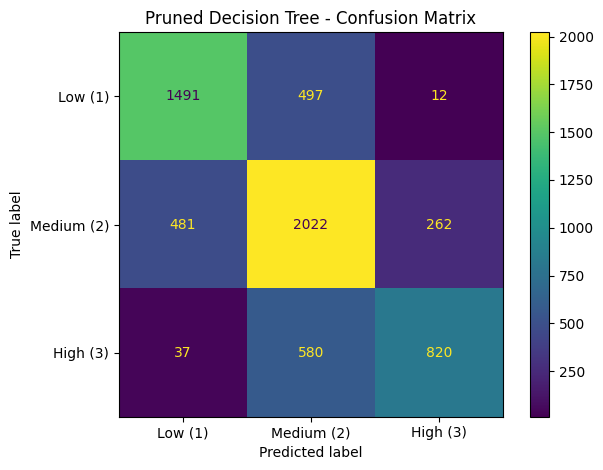

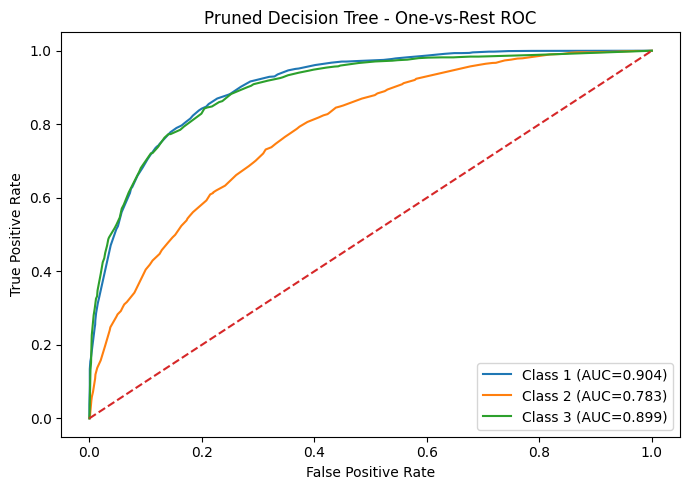

Macro ROC-AUC: 0.8619
Nodes: 189
Leaves: 95
Depth: 8


In [14]:
REPORT_CCP_ALPHA = 5.95e-4

pruned_tree_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=8,
    min_samples_split=0.01,
    min_samples_leaf=30,
    ccp_alpha=REPORT_CCP_ALPHA,
    random_state=RANDOM_STATE,
)

pruned_tree_model.fit(X_train, y_train)

pruned_tree_metrics = evaluate_classifier(
    pruned_tree_model,
    X_test,
    y_test,
    "Pruned Decision Tree",
)

plot_multiclass_roc(
    pruned_tree_model,
    X_test,
    y_test,
    "Pruned Decision Tree",
)

print("Nodes:", pruned_tree_model.tree_.node_count)
print("Leaves:", pruned_tree_model.get_n_leaves())
print("Depth:", pruned_tree_model.get_depth())


,importance
NumDemand,0.328123
YearPublished,0.220211
Ranking,0.215593
GameWeight,0.178164
NumOwned,0.028867
MaxPlayers,0.017869
AvgPlaytime,0.009081
NumExpansions,0.001179
NumImplementations,0.000914
MfgAgeRec,0.000000


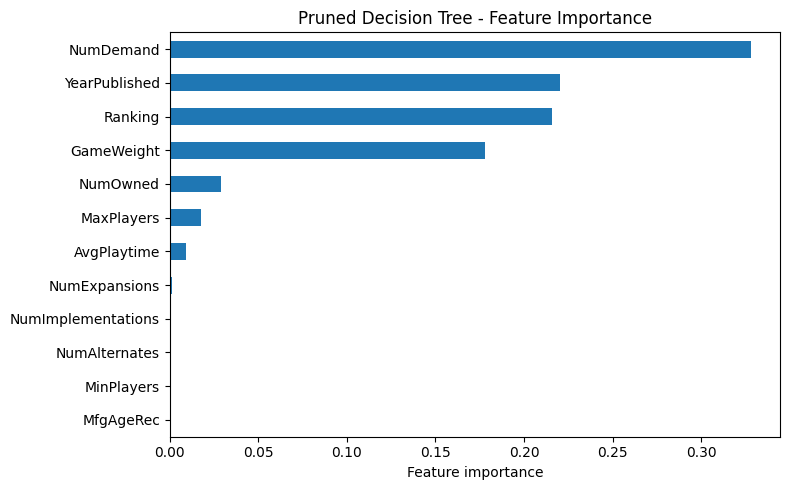

In [15]:
feature_importance = (
    pd.Series(
        pruned_tree_model.feature_importances_,
        index=COMMON_FEATURES,
        name="importance",
    )
    .sort_values(ascending=False)
)

display(feature_importance.to_frame())

plt.figure(figsize=(8, 5))
feature_importance.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Pruned Decision Tree - Feature Importance")
plt.tight_layout()
plt.show()


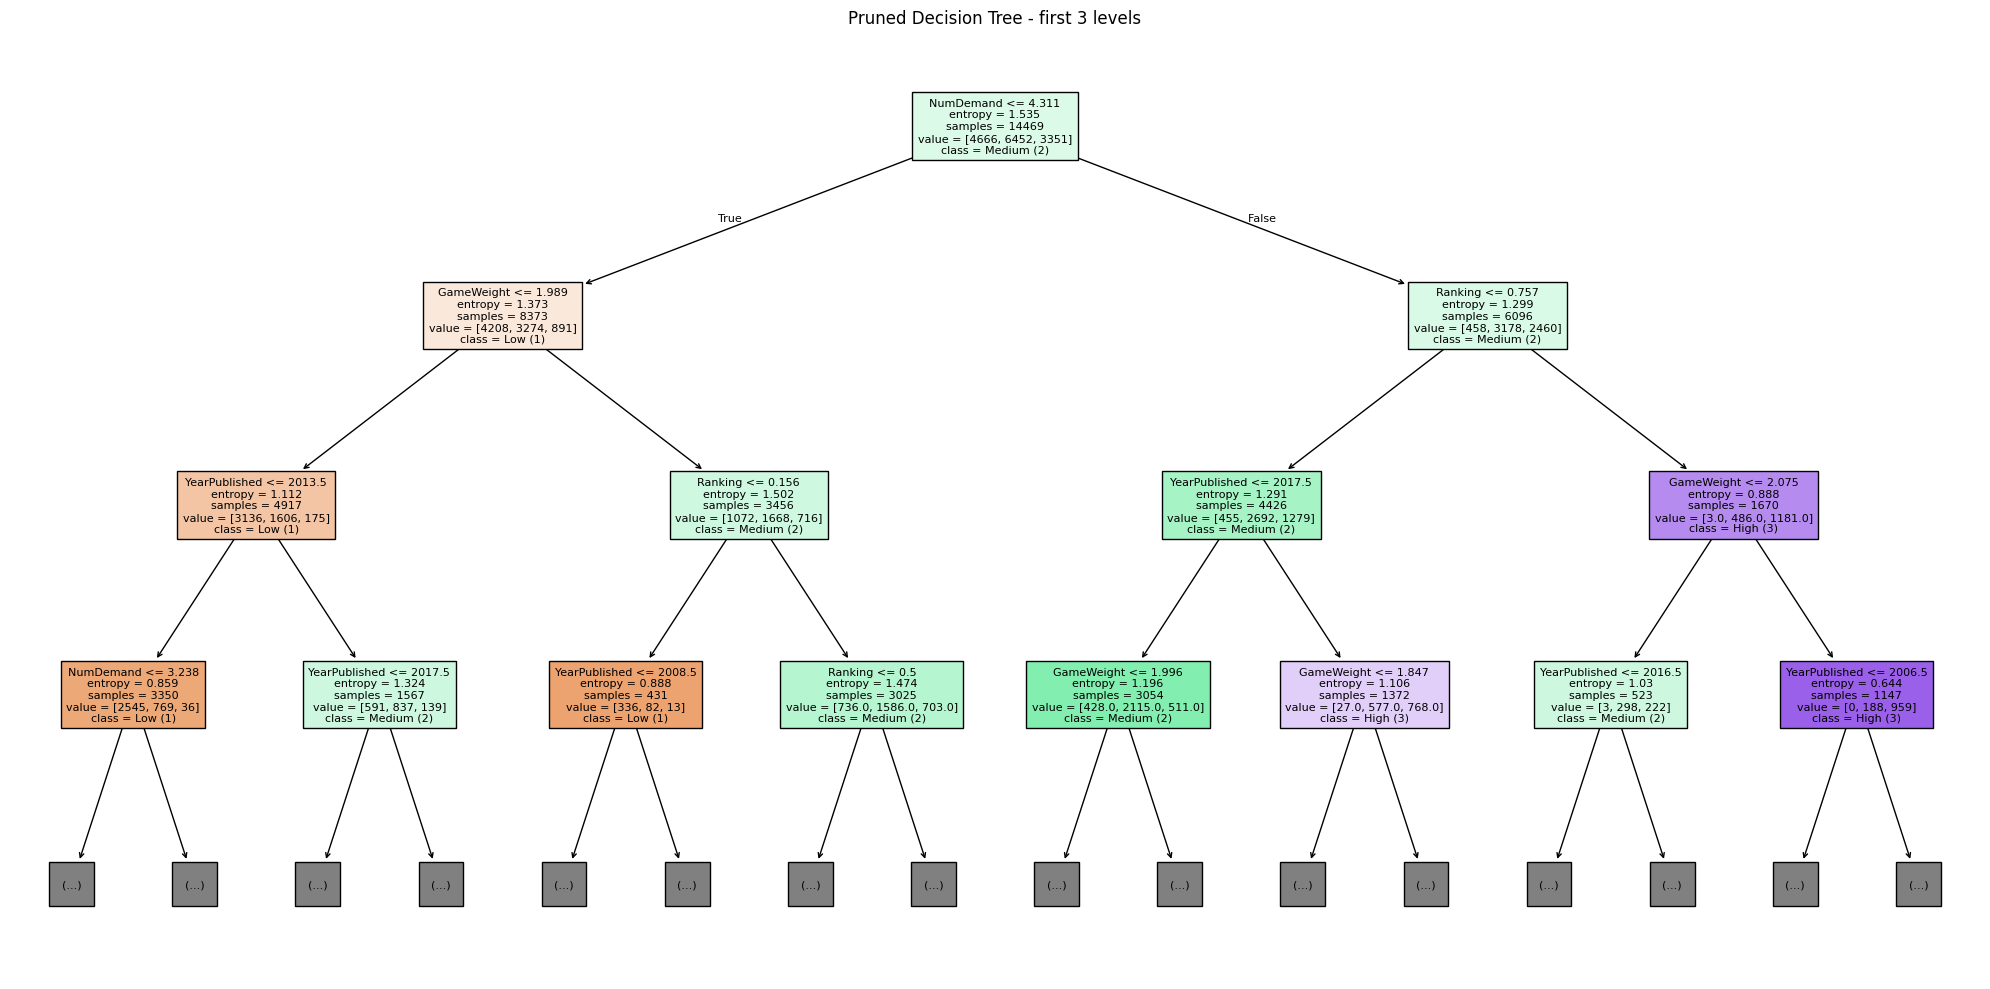

In [16]:
plt.figure(figsize=(20, 10))
plot_tree(
    pruned_tree_model,
    feature_names=COMMON_FEATURES,
    class_names=CLASS_NAMES,
    filled=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Pruned Decision Tree - first 3 levels")
plt.tight_layout()
plt.show()


## 4.4 Final Comparison

In [17]:
comparison = pd.DataFrame([
    knn_metrics,
    gaussian_nb_metrics,
    categorical_nb_metrics,
    tree_metrics,
    pruned_tree_metrics,
]).sort_values("macro_f1", ascending=False)

display(comparison.reset_index(drop=True))


,model,accuracy,macro_f1
0,KNN,0.717672,0.714712
1,Decision Tree (entropy),0.700419,0.696653
2,Pruned Decision Tree,0.698646,0.693808
3,Categorical Naive Bayes (10 quantile bins),0.642857,0.646377
4,Gaussian Naive Bayes,0.612061,0.613645


### Final Interpretation
We encountered a recurring difficulty in predicting the **Medium** rating class, whose observations overlap with both low- and high-rated games.

- KNN separates the extreme classes relatively well but tends to favour the intermediate class in ambiguous regions.
- Naïve Bayes is more limited because the dataset contains dependencies and correlated structures that conflict with its simplifying assumptions; discretization improves results only moderately.
- The Decision Tree captures non-linear interactions and explicit thresholds more naturally. We also noted that `Ranking` materially improves this model and that pruning reduces complexity without degrading test performance.